# Food Image Classification: Computer Vision Assignment

**Classes:** burger, hotdog, pizza, sandwich, sushi

**Pipeline:** dataset validation -> train/val/test split -> preprocessing & augmentation ->
baseline model (SVM + HOG) -> improved model (EfficientNet-B0 transfer learning) -> evaluation & error analysis.

Each stage below calls the corresponding project script (`prepare_dataset.py`, `split_dataset.py`,
`preprocessing.py`, `baseline_svm.py`, `train_efficientnet.py`, `analyze_errors.py`) so the notebook
and the standalone scripts stay in sync, then loads and displays the resulting metrics/plots.

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display
import pandas as pd

RESULTS = Path("results")

## Step 1 - Dataset Validation

In [2]:
import prepare_dataset
prepare_dataset.main()

ModuleNotFoundError: No module named 'prepare_dataset'

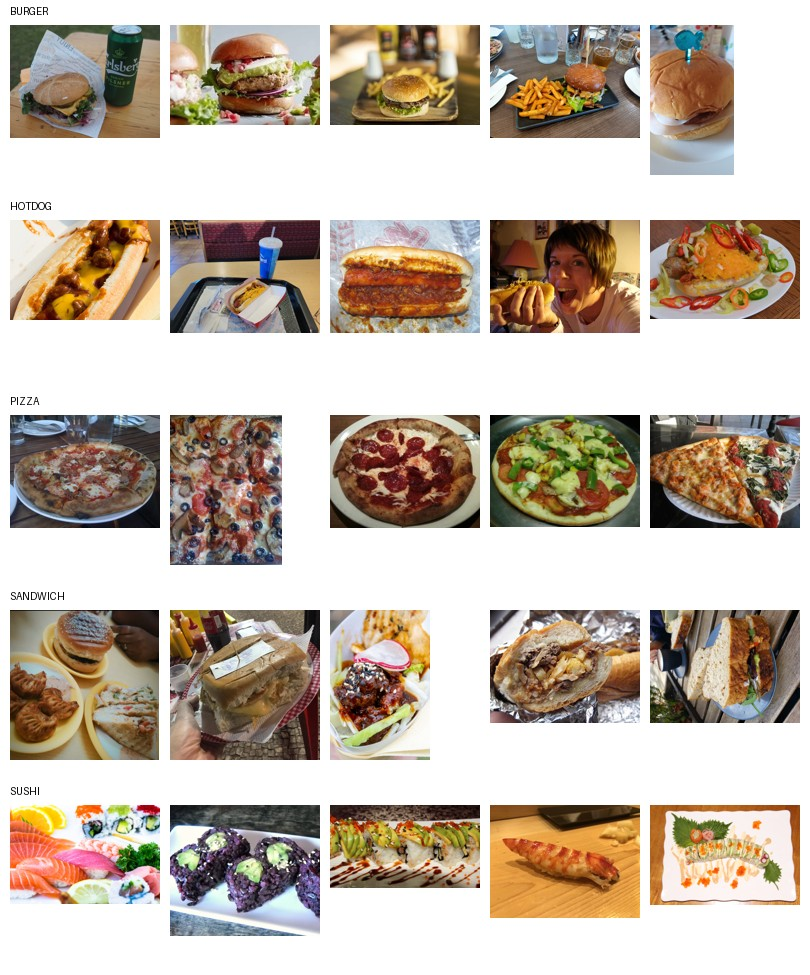

In [ ]:
display(Image(filename=str(RESULTS / "dataset_preview.jpg")))

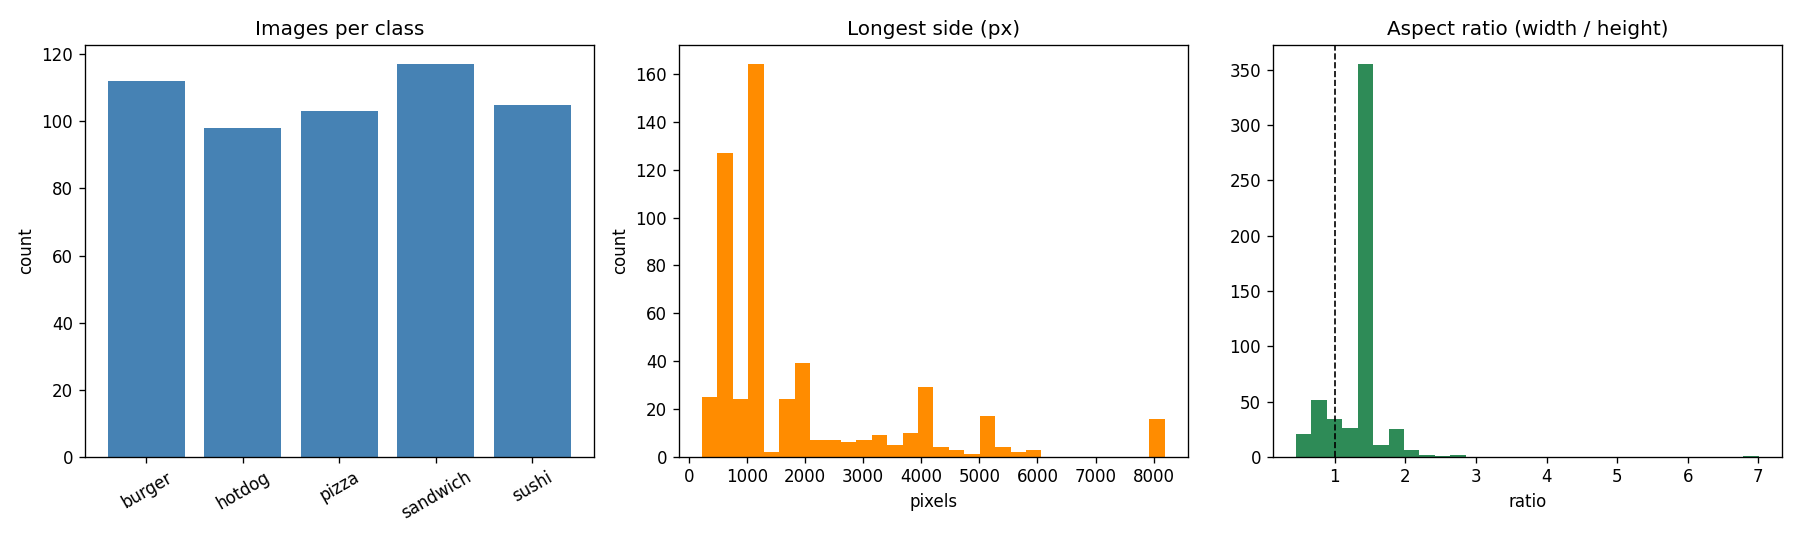

In [ ]:
display(Image(filename=str(RESULTS / "dataset_eda.png")))

In [ ]:
print((RESULTS / "dataset_report.txt").read_text())

DATASET SUMMARY REPORT

Total images scanned: 535
Valid images: 535
Corrupted/invalid images: 0

Images per class:
  Burger     112
  Hotdog     98
  Pizza      103
  Sandwich   117
  Sushi      105

Class balance -- min: 98, max: 117, diff: 19

Corrupted images:
  None

Exact duplicate groups: 0

Possible visually-similar pairs (Hamming distance <= 5): 0

Dimension statistics per class:
  Burger:
    Min:     183x159
    Max:     1280x2276
    Average: 1040x844
    Unusual (< 200px on a side): 11
  Hotdog:
    Min:     256x256
    Max:     1280x1707
    Average: 701x533
    Unusual (< 200px on a side): 0
  Pizza:
    Min:     383x341
    Max:     1280x2208
    Average: 940x805
    Unusual (< 200px on a side): 0
  Sandwich:
    Min:     400x266
    Max:     8192x8160
    Average: 3375x2702
    Unusual (< 200px on a side): 0
  Sushi:
    Min:     320x240
    Max:     5760x3840
    Average: 2797x1927
    Unusual (< 200px on a side): 0

File format statistics:
  JPEG: 520
  PNG: 8
  MPO: 

**Manual data-quality review:** the automated validation above only checks technical
properties (corruption, duplicates, dimensions); it cannot tell whether an image actually
shows the right food. A full visual review of every class found that the `sandwich` class
in particular contained a substantial fraction of irrelevant images (street/town photos,
paintings, illustrations, memes, and even a dog with a toy), most likely pulled in because
"Sandwich" is also a place name (e.g. Sandwich, Kent / Sandwich, MA), which is ambiguous for
keyword-based image collection. 30 irrelevant images were removed from `sandwich` and 1 from
`pizza` (a restaurant-interior photo with no pizza visible).

A second pass over the automated validation report above also found two **near-duplicate
pairs in `hotdog`** (perceptual-hash distance 0, visually identical photos saved twice)
and **one near-unusable 100x100 thumbnail in `burger`**; these 3 images were removed too.
Images that are merely small but genuinely show the right food (e.g. several other `burger`
photos around 180-300px) were kept, since the model resizes to 224x224 regardless and
removing correctly-labeled data would only shrink the dataset without fixing anything.
The full list of all 34 removed files and the reason for each is tracked in
`removed_files.csv` at the project root, so the cleanup is reproducible and auditable.

**Data provenance:** several images (e.g. `hotdog_077.jpg`, which carries a visible
"(C) 2009 Foodnut.com" watermark) were sourced from the public web rather than
photographed by the student. This is disclosed here rather than claiming a fully
self-photographed dataset.

The dataset below reflects all of these removals before the split.

## Step 2 - Train / Val / Test Split

In [ ]:
import split_dataset
split_dataset.main()

Class       Train    Val   Test  Total
burger         78     17     17    112
hotdog         69     15     14     98
pizza          72     15     16    103
sandwich       82     18     17    117
sushi          74     16     15    105

Total: train=375, val=81, test=79

Split written to: dataset_split/


## Step 3 - Preprocessing & Augmentation

In [ ]:
import preprocessing
preprocessing.main()

Computing dataset mean/std from train split...
Dataset mean: [0.5846, 0.4656, 0.3489]
Dataset std:  [0.2539, 0.253, 0.263]
Normalization stats written to: results/normalization_stats.json

Train transform pipeline:
  - RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.3333), interpolation=bilinear, antialias=True)
  - RandomHorizontalFlip(p=0.5)
  - RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
  - ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2), saturation=(0.8, 1.2), hue=None)
  - ToTensor()
  - Normalize(mean=[0.5845664739608765, 0.46563854813575745, 0.34892943501472473], std=[0.2539352476596832, 0.2529754042625427, 0.2629520893096924])

Eval transform pipeline (val/test):
  - Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
  - CenterCrop(size=(224, 224))
  - ToTensor()
  - Normalize(mean=[0.5845664739608765, 0.46563854813575745, 0.34892943501472473], std=[0.2539352476596832, 0.2529754042625427, 0.

**Note on the two normalization statistics printed above:** `preprocessing.py` computes and
prints the dataset's *own* mean/std for illustration (what you'd use if training a CNN from
scratch). The EfficientNet-B0 model trained in Step 5 is **pretrained on ImageNet**, so it
uses the standard **ImageNet** mean/std instead (its `train_efficientnet.py` has its own
`build_transforms()`, consistent with ImageNet normalization). This is not a contradiction,
just two different pipelines for two different models, as `normalization_stats.json` notes.

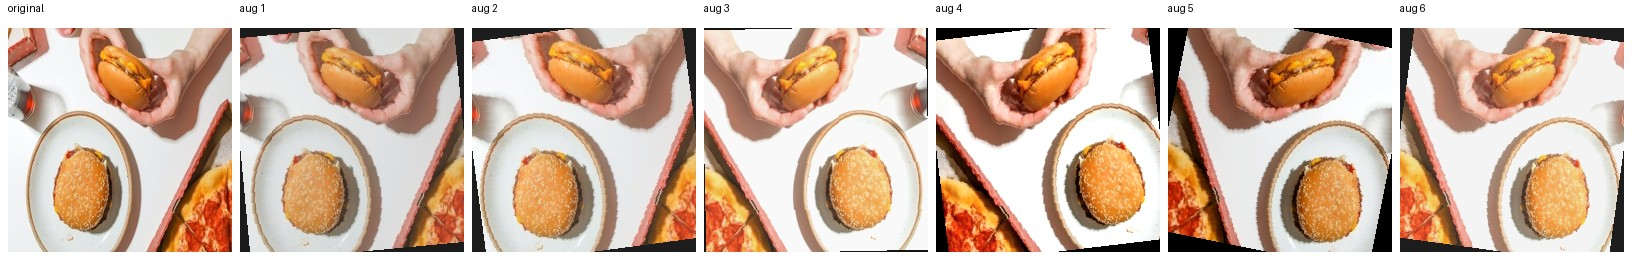

In [ ]:
display(Image(filename=str(RESULTS / "augmentation_preview.jpg")))

## Step 4 - Baseline Model (SVM + HOG features)

A classical (non-deep-learning) baseline: HOG (Histogram of Oriented Gradients) features
extracted from grayscale images, classified with an RBF-kernel SVM.

In [ ]:
import baseline_svm
baseline_svm.main()

Loading train split and extracting HOG features...
Train features: (375, 1764)
Loading val split...
Loading test split...

Training SVM (RBF kernel)...

TRAIN results:
  Accuracy:  1.0000
  Precision (macro): 1.0000
  Recall (macro):    1.0000
  F1 (macro):        1.0000
  Confusion matrix:
[[78  0  0  0  0]
 [ 0 69  0  0  0]
 [ 0  0 72  0  0]
 [ 0  0  0 82  0]
 [ 0  0  0  0 74]]
              precision    recall  f1-score   support

      burger       1.00      1.00      1.00        78
      hotdog       1.00      1.00      1.00        69
       pizza       1.00      1.00      1.00        72
    sandwich       1.00      1.00      1.00        82
       sushi       1.00      1.00      1.00        74

    accuracy                           1.00       375
   macro avg       1.00      1.00      1.00       375
weighted avg       1.00      1.00      1.00       375


VAL results:
  Accuracy:  0.4815
  Precision (macro): 0.4959
  Recall (macro):    0.4831
  F1 (macro):        0.4783
  Confusio

In [ ]:
with open(RESULTS / "baseline_svm_metrics.json") as f:
    svm_metrics = json.load(f)

pd.DataFrame({
    split: {
        "accuracy": svm_metrics[split]["accuracy"],
        "precision_macro": svm_metrics[split]["precision_macro"],
        "recall_macro": svm_metrics[split]["recall_macro"],
        "f1_macro": svm_metrics[split]["f1_macro"],
    }
    for split in ["train", "val", "test"]
}).T

,accuracy,precision_macro,recall_macro,f1_macro
train,1.000000,1.000000,1.000000,1.000000
val,0.481481,0.495918,0.483105,0.478251
test,0.531646,0.528654,0.519083,0.501976


## Step 5 - Improved Model (EfficientNet-B0, transfer learning)

Pretrained on ImageNet, then fine-tuned in two phases:

1. Head-only (10 epochs, LR 1e-3): the backbone is frozen (requires_grad=False) and its
   BatchNorm layers are explicitly kept in eval() mode, so the pretrained running mean and
   variance statistics are not drifted by our small, non-ImageNet-like batches before any
   backbone weight is actually updated.
2. Full fine-tune (up to 15 epochs, LR 1e-4, cosine-annealed, early stopping with patience
   5 on val accuracy): the whole network is unfrozen and BatchNorm returns to normal
   training behavior.

The best checkpoint across both phases, by validation accuracy, is kept. In both runs
below (with and without augmentation), that turned out to be a head-only checkpoint:
fine-tuning the full backbone never beat the best head-only epoch on val, and in the
no-augmentation run val accuracy actually got worse once the backbone was unfrozen. With
only 375 training images, updating roughly 4 million backbone parameters appears to be
more likely to overfit or drift away from the useful ImageNet features than to help, at
least at the learning rates tried here. The deployed model is effectively a linear
classifier on top of frozen ImageNet features, not a fully fine-tuned network.

Using device: mps
Augmentation enabled: True

=== Phase 1: training classifier head (backbone frozen) ===
[head] epoch 1/10 - train_loss=1.3147 train_acc=0.5227 val_loss=0.9765 val_acc=0.7407
[head] epoch 2/10 - train_loss=0.7924 train_acc=0.8080 val_loss=0.7488 val_acc=0.7654
[head] epoch 3/10 - train_loss=0.5941 train_acc=0.8293 val_loss=0.6548 val_acc=0.7901
[head] epoch 4/10 - train_loss=0.5065 train_acc=0.8453 val_loss=0.6022 val_acc=0.7654
[head] epoch 5/10 - train_loss=0.4398 train_acc=0.8560 val_loss=0.5772 val_acc=0.7654
[head] epoch 6/10 - train_loss=0.3784 train_acc=0.9040 val_loss=0.5739 val_acc=0.7778
[head] epoch 7/10 - train_loss=0.3368 train_acc=0.9173 val_loss=0.5557 val_acc=0.7531
[head] epoch 8/10 - train_loss=0.3120 train_acc=0.9173 val_loss=0.5395 val_acc=0.7778
[head] epoch 9/10 - train_loss=0.2905 train_acc=0.9333 val_loss=0.5382 val_acc=0.7778
[head] epoch 10/10 - train_loss=0.2619 train_acc=0.9413 val_loss=0.5385 val_acc=0.7778

=== Phase 2: fine-tuning full ne

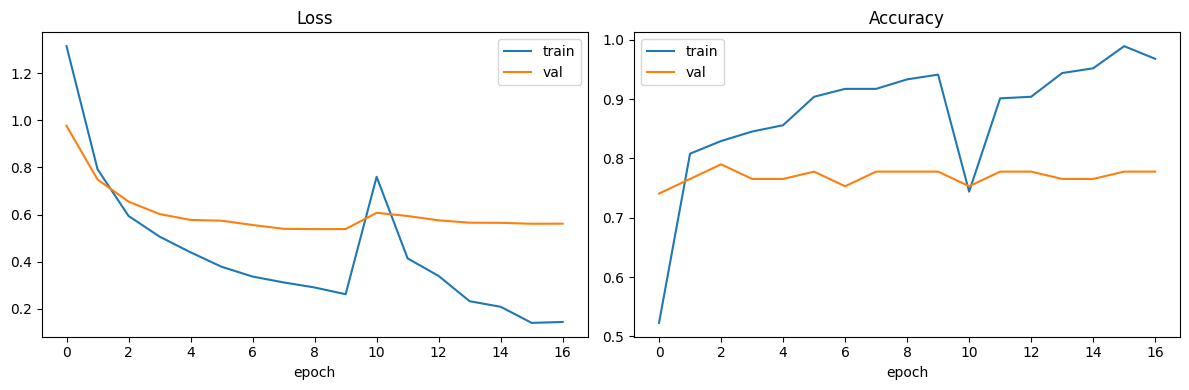

In [ ]:
import train_efficientnet
train_efficientnet.main();

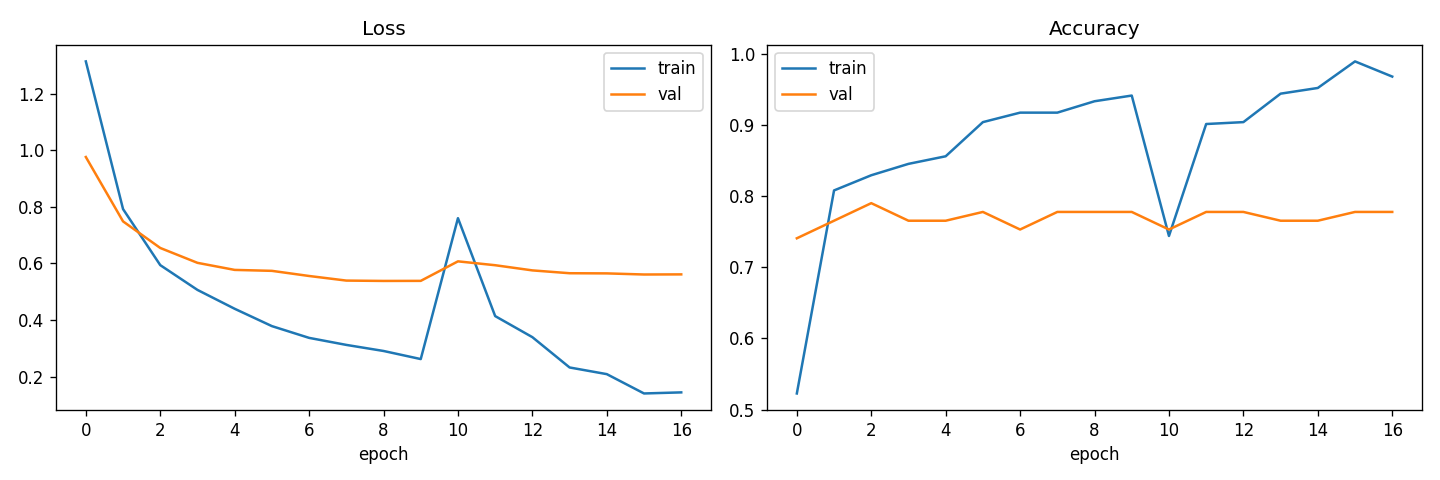

In [ ]:
display(Image(filename=str(RESULTS / "efficientnet_training_curves.png")))

In [ ]:
with open(RESULTS / "efficientnet_metrics.json") as f:
    effnet_metrics = json.load(f)

pd.DataFrame({
    split: {
        "accuracy": effnet_metrics[split]["accuracy"],
        "precision_macro": effnet_metrics[split]["precision_macro"],
        "recall_macro": effnet_metrics[split]["recall_macro"],
        "f1_macro": effnet_metrics[split]["f1_macro"],
    }
    for split in ["train", "val", "test"]
}).T

,accuracy,precision_macro,recall_macro,f1_macro
train,0.882667,0.887891,0.888697,0.883790
val,0.790123,0.811733,0.804069,0.791154
test,0.784810,0.791543,0.795175,0.780103


### Step 5b - Augmentation ablation: with vs. without

The same architecture, seed, epoch budget and early-stopping rule, trained a second time
with augmentation disabled (train uses the same deterministic Resize(256)+CenterCrop(224)
as eval, instead of RandomResizedCrop/flip/rotation/color-jitter).

Using device: mps
Augmentation enabled: False

=== Phase 1: training classifier head (backbone frozen) ===
[head] epoch 1/10 - train_loss=1.2624 train_acc=0.5867 val_loss=0.9189 val_acc=0.7654
[head] epoch 2/10 - train_loss=0.7003 train_acc=0.8480 val_loss=0.6815 val_acc=0.8025
[head] epoch 3/10 - train_loss=0.5058 train_acc=0.8747 val_loss=0.6026 val_acc=0.7778
[head] epoch 4/10 - train_loss=0.4010 train_acc=0.8960 val_loss=0.5689 val_acc=0.7778
[head] epoch 5/10 - train_loss=0.3544 train_acc=0.8987 val_loss=0.5401 val_acc=0.7654
[head] epoch 6/10 - train_loss=0.3127 train_acc=0.9227 val_loss=0.5247 val_acc=0.7654
[head] epoch 7/10 - train_loss=0.2811 train_acc=0.9227 val_loss=0.5179 val_acc=0.7778
[head] epoch 8/10 - train_loss=0.2512 train_acc=0.9440 val_loss=0.5113 val_acc=0.8148
[head] epoch 9/10 - train_loss=0.2167 train_acc=0.9547 val_loss=0.5094 val_acc=0.7778
[head] epoch 10/10 - train_loss=0.2088 train_acc=0.9520 val_loss=0.5099 val_acc=0.8025

=== Phase 2: fine-tuning full n

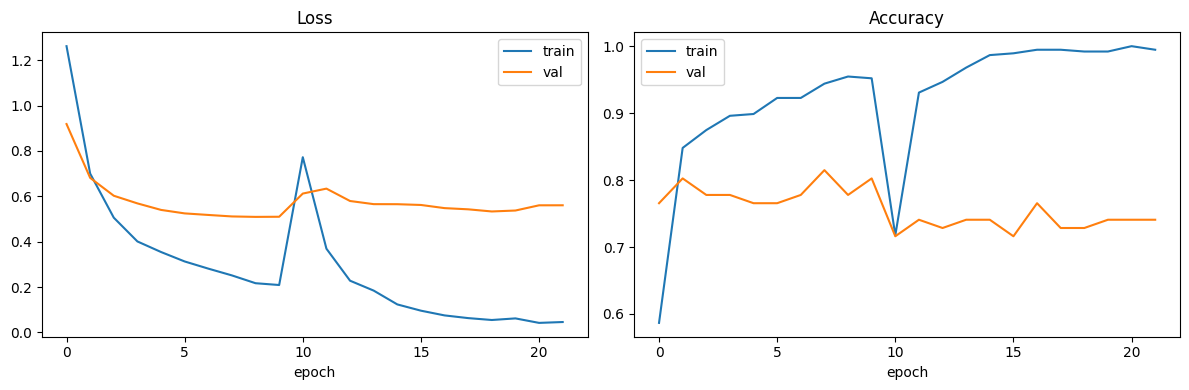

In [ ]:
import train_efficientnet
train_efficientnet.main(augment=False, suffix="_noaug");

In [ ]:
with open(RESULTS / "efficientnet_noaug_metrics.json") as f:
    noaug_metrics = json.load(f)

pd.DataFrame({
    "with augmentation": {
        "train_acc": effnet_metrics["train"]["accuracy"],
        "val_acc": effnet_metrics["val"]["accuracy"],
        "test_acc": effnet_metrics["test"]["accuracy"],
        "train-val gap": effnet_metrics["train"]["accuracy"] - effnet_metrics["val"]["accuracy"],
    },
    "without augmentation": {
        "train_acc": noaug_metrics["train"]["accuracy"],
        "val_acc": noaug_metrics["val"]["accuracy"],
        "test_acc": noaug_metrics["test"]["accuracy"],
        "train-val gap": noaug_metrics["train"]["accuracy"] - noaug_metrics["val"]["accuracy"],
    },
}).T

,train_acc,val_acc,test_acc,train-val gap
with augmentation,0.882667,0.790123,0.784810,0.092543
without augmentation,0.954667,0.814815,0.898734,0.139852


Augmentation reduced overfitting (train-val gap 0.09 with augmentation vs 0.14 without) but
did not improve accuracy in this setup: val 0.790 vs 0.815, test 0.785 vs 0.899, augmentation
scoring lower both times. Likely reasons: a small dataset (375 training images), a frozen
backbone in both final checkpoints (see Step 5), and a single training run per configuration
rather than an average over several seeds. This is a case where the textbook expectation
("augmentation should help generalization") and the actual numbers disagree, and the honest
reading is that augmentation helped the one thing it is supposed to help (the train-val gap)
without translating into higher accuracy here, at least not in a single run on a dataset
this size.

## Step 6 - Error Analysis & Model Comparison

In [ ]:
import analyze_errors
analyze_errors.main()

Confusion matrix heatmaps saved.
Model comparison written to results/model_comparison.json

Loading EfficientNet model and test set to find misclassified examples...
Misclassified on test: 17 / 79
Misclassified examples sheet saved to: results/misclassified_examples.jpg

Most common confusion pairs (true -> predicted):
  sandwich -> burger: 9
  burger -> sandwich: 2
  burger -> hotdog: 1
  hotdog -> pizza: 1
  pizza -> sandwich: 1
  sandwich -> hotdog: 1
  sandwich -> sushi: 1
  sushi -> pizza: 1
Error analysis summary written to results/error_analysis.json


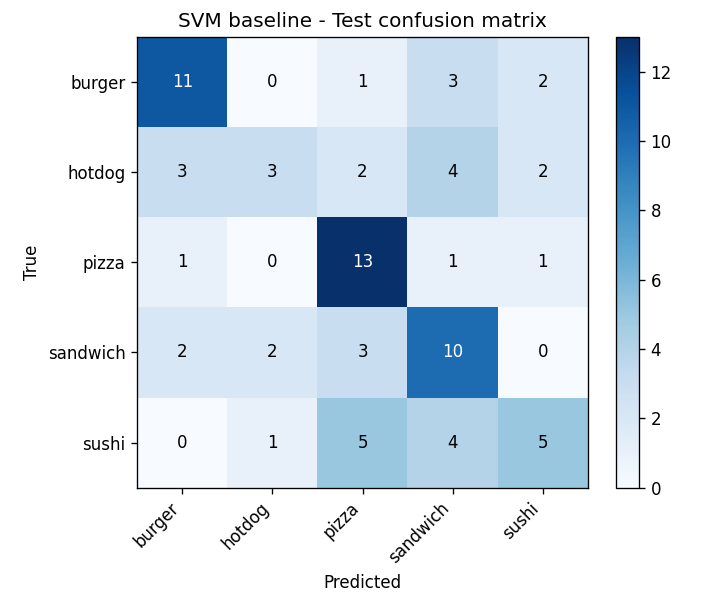

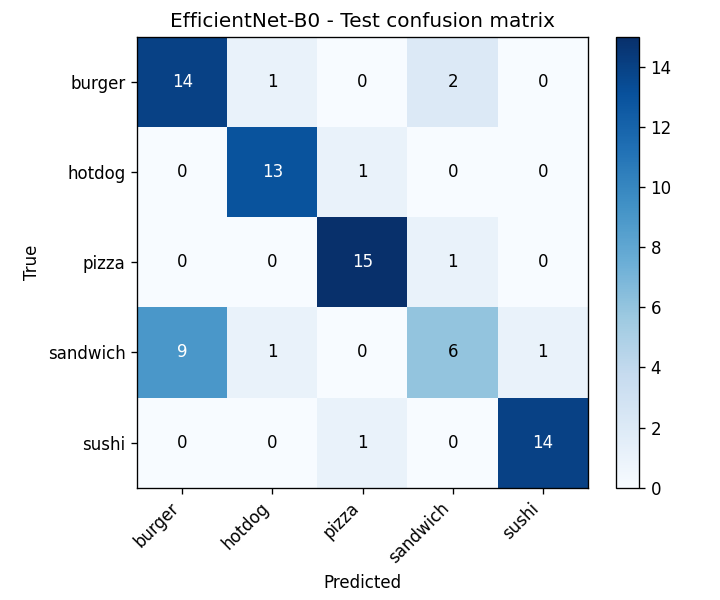

In [ ]:
display(Image(filename=str(RESULTS / "confusion_matrix_svm_test.png")))
display(Image(filename=str(RESULTS / "confusion_matrix_efficientnet_test.png")))

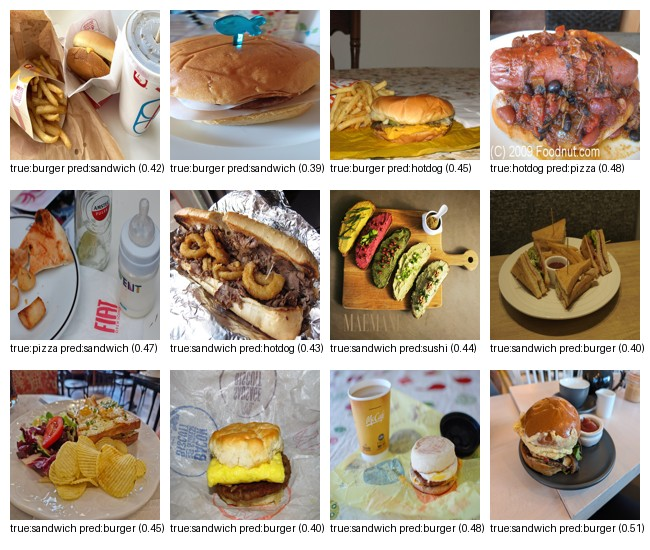

In [ ]:
display(Image(filename=str(RESULTS / "misclassified_examples.jpg")))

In [ ]:
with open(RESULTS / "model_comparison.json") as f:
    comparison = json.load(f)
pd.DataFrame(comparison).T

,accuracy,precision_macro,recall_macro,f1_macro
svm_test,0.531646,0.528654,0.519083,0.501976
efficientnet_test,0.784810,0.791543,0.795175,0.780103


In [ ]:
with open(RESULTS / "error_analysis.json") as f:
    error_analysis = json.load(f)

print(f"Misclassified: {error_analysis['total_misclassified']} / {error_analysis['total_test_samples']}")
pd.Series(error_analysis["confusion_pairs"]).sort_values(ascending=False)

Misclassified: 17 / 79


sandwich -> burger    9
burger -> sandwich    2
burger -> hotdog      1
hotdog -> pizza       1
pizza -> sandwich     1
sandwich -> hotdog    1
sandwich -> sushi     1
sushi -> pizza        1
dtype: int64

### Bootstrap confidence intervals for test accuracy

The test set is only 79 images, so a single accuracy number hides how much that number
would wobble on a different random sample. A simple nonparametric bootstrap (resample the
79 correct/incorrect outcomes with replacement, 10000 times) gives a 95% interval for each
model.

In [ ]:
import numpy as np

def bootstrap_ci(acc, n, n_boot=10000, seed=42):
    rng = np.random.default_rng(seed)
    correct = np.zeros(n)
    correct[: round(acc * n)] = 1
    rng.shuffle(correct)
    boot_accs = [rng.choice(correct, size=n, replace=True).mean() for _ in range(n_boot)]
    lo, hi = np.percentile(boot_accs, [2.5, 97.5])
    return lo, hi

n_test = error_analysis["total_test_samples"]
rows = {
    "SVM + HOG": svm_metrics["test"]["accuracy"],
    "EfficientNet, with augmentation": effnet_metrics["test"]["accuracy"],
    "EfficientNet, without augmentation": noaug_metrics["test"]["accuracy"],
}
ci_table = {}
for name, acc in rows.items():
    lo, hi = bootstrap_ci(acc, n_test)
    ci_table[name] = {"test_acc": round(acc, 3), "ci_low": round(lo, 3), "ci_high": round(hi, 3)}
pd.DataFrame(ci_table).T

,test_acc,ci_low,ci_high
SVM + HOG,0.532,0.418,0.646
"EfficientNet, with augmentation",0.785,0.696,0.873
"EfficientNet, without augmentation",0.899,0.823,0.962


The EfficientNet models clearly beat the SVM baseline (no overlap in intervals). The two
EfficientNet variants (with and without augmentation) have overlapping intervals, which is
the honest statistical statement here: this single 79-image test set cannot confidently
tell the two apart, even though the point estimates differ by more than 10 points.

## Conclusion

- Baseline (SVM + HOG) reached 53% test accuracy, clearly better than chance (20% for 5
  classes) but still weak, and it overfit heavily (100% train accuracy vs 53% test).
- Improved model (EfficientNet-B0, transfer learning): 78.5% test accuracy with
  augmentation, 89.9% without, in this single run each (see the bootstrap table above for
  how much that gap could be noise). In both cases the checkpoint that was actually kept
  came from the head-only phase, not from full fine-tuning (Step 5): fine-tuning the whole
  backbone on 375 images never beat the frozen-backbone result on validation, and for the
  no-augmentation run it made things worse.
- Augmentation reduced the train-val gap (0.09 vs 0.14) as expected, but did not improve
  accuracy in this setup (Step 5b). The most likely explanation is the combination of a
  small dataset, a frozen backbone, and a single run per configuration, not that
  augmentation is useless in general.
- 34 images were removed in manual review (31 irrelevant "Sandwich"-the-place-name or
  restaurant-interior photos, 2 near-duplicate hotdog photos, 1 unusable 100x100 burger
  thumbnail; full list with reasons in removed_files.csv), and an aspect-ratio-distorting
  preprocessing bug was fixed. We do not claim a clean before/after accuracy number for
  this cleanup, because the dataset, the preprocessing pipeline, and the test set itself
  (84 to 79 images) all changed at the same time; a rigorous ablation would need to vary
  one factor at a time on a fixed split, which was out of scope here. The case for cleaning
  stands on its own regardless: every removed image provably did not show the labeled food
  (a painting, a street scene, a duplicate, an unusable thumbnail).
- Burger vs sandwich remains the dominant confusion in every configuration tried (baseline,
  improved, with or without augmentation). Both classes genuinely look similar (bread and
  filling, plated with sides), which looks like a real visual ambiguity in the data rather
  than a data-quality or pipeline artifact.
- Known limitations: the test set is small (79 images) and the bootstrap intervals above
  show the two EfficientNet variants are not reliably distinguishable on it; SVM
  hyperparameters (C, gamma) were fixed rather than tuned via grid search; torch seeding
  makes runs more reproducible but GPU/MPS kernels are not perfectly bit-deterministic, so
  exact numbers can still shift slightly run to run; at least one hotdog image is a
  watermarked web photo rather than self-photographed (Section 2.3 in the report).

---

Claude (Anthropic) was used as an assistant throughout this project: writing and debugging
the pipeline scripts, reviewing the dataset for quality issues, and drafting this notebook
and the accompanying report.